# COPA-DATA filler M7: finding the anomalies in the real data

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leon-adsk/copa/blob/jbt/notebooks/anomaly_findings_colab.ipynb)

Press ▶ on each cell from top to bottom (or *Run All*). Works in VS Code (local Python kernel or the Colab extension)
and on colab.research.google.com.

* **Data:** the six raw zenon files from COPA-DATA in `data/txt` (Git LFS). Nothing is simulated or renamed.
* **Names:** every column is the real variable name from the files (for example `Sim/Global/M7_CompAir`).
* **Label:** Andreas Grün, mail 13.11.2026: *"There were plenty anomalies over and over again between October 29 and
  November 4th ~10:50; after that, so Nov 4 ~10:50 - 15:00, no anomalies occurred anymore."* That covers the export of
  04.11.2026 (it ends 04.11.2026 15:00). The export of 20.11.2026 starts at 15:00; Andreas said nothing about it.

In [1]:
# @title Setup: find the repo locally, or clone it on a Colab server
BRANCH = "jbt"                          # branch with analysis/ (push it first)
REPO_URL = "github.com/leon-adsk/copa.git"

import os, sys, shutil, subprocess, getpass
from pathlib import Path

def find_local_repo():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "analysis" / "copa_data.py").exists() and (p / "data" / "txt").exists():
            return p
    return None

REPO = find_local_repo()
WHERE = "local repo"
if REPO is None:                         # remote runtime (Colab): clone the private repo
    WHERE = f"cloned from GitHub (branch {BRANCH})"
    REPO = Path("/content/copa")
    if not (REPO / "analysis").exists():
        try:                             # Colab secret "GITHUB_TOKEN" ...
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:                # ... otherwise type it in (not stored in the notebook)
            token = getpass.getpass("GitHub token with read access to leon-adsk/copa: ")
        if shutil.which("git-lfs") is None:
            subprocess.run("apt-get -qq install -y git-lfs", shell=True, check=True)
        r = subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, f"https://{token}@{REPO_URL}", str(REPO)],
                           env={**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"}, capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError(f"git clone failed: check the token and that branch '{BRANCH}' is pushed")
        subprocess.run(["git", "lfs", "install", "--local"], cwd=REPO, check=True, capture_output=True)
        subprocess.run(["git", "lfs", "pull", "--include", "data/txt/*"], cwd=REPO, check=True, capture_output=True)
        subprocess.run(["git", "remote", "set-url", "origin", f"https://{REPO_URL}"], cwd=REPO, check=True)
        del token
os.chdir(REPO)
sys.path.insert(0, str(REPO / "analysis"))
print("using:", WHERE)

using: local repo


## 1 · The raw files, as delivered
Each row is `Date; Time; Variable name; value; Status` (Andreas, mail 13.11.2026). Rows whose Status contains
`INVALID` are ignored, as Andreas asked.

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 250)

files = sorted(Path("data/txt").glob("*.TXT"))
raw = pd.concat([pd.read_csv(f, sep=";", header=None, names=["Date", "Time", "Variable name", "value", "Status"]).assign(file=f.name)
                 for f in files], ignore_index=True)
raw["Status"] = raw["Status"].str.strip()
raw["timestamp"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d.%m.%Y %H:%M:%S.%f")
raw["INVALID"] = raw["Status"].str.contains("INVALID")
display(raw.head(8))
display(raw.groupby("file").agg(rows=("value", "size"), INVALID_rows=("INVALID", "sum"),
                                first=("timestamp", "min"), last=("timestamp", "max")))

,Date,Time,Variable name,value,Status,file,timestamp,INVALID
0,29.10.2026,06:53:09.574,M07.WS_Cur_State,262144.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:53:09.574,False
1,29.10.2026,06:53:11.543,M07.WS_Cur_State,128.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:53:11.543,False
2,29.10.2026,06:58:38.317,M07.WS_Cur_State,131072.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:58:38.317,False
3,29.10.2026,06:58:39.417,M07.WS_Cur_State,8.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:58:39.417,False
4,29.10.2026,06:53:11.543,M07.WS_Cur_Prog,1.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 06:53:11.543,False
5,29.10.2026,07:00:00.000,M07.WS_Cur_State,8.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 07:00:00.000,False
6,29.10.2026,07:00:24.535,M07.WS_Cur_State,262144.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 07:00:24.535,False
7,29.10.2026,07:00:26.505,M07.WS_Cur_State,128.0,SPONT T_STD_E T_EXTERN T_STD,07261104141229_07.TXT,2026-10-29 07:00:26.505,False


,rows,INVALID_rows,first,last
file,,,,
07261104141229_07.TXT,4673,0,2026-10-29 06:53:09.574,2026-11-04 15:00:00
07261120103434_07.TXT,11865,6,2026-11-04 15:00:00.000,2026-11-20 11:00:00
17261104141251_17.TXT,730242,0,2026-10-29 06:50:00.000,2026-11-04 15:00:00
17261120103538_17.TXT,547204,1088,2026-11-04 15:00:00.000,2026-11-20 11:00:00
FP261104141238_FP.TXT,2007441,0,2026-10-29 06:50:00.000,2026-11-04 15:00:00
FP261120103526_FP.TXT,1504811,2992,2026-11-04 15:00:00.000,2026-11-20 11:00:00


In [3]:
# which variable is in which file (number of rows)
display(raw.pivot_table(index="Variable name", columns="file", values="value", aggfunc="size", fill_value=0))

file,07261104141229_07.TXT,07261120103434_07.TXT,17261104141251_17.TXT,17261120103538_17.TXT,FP261104141238_FP.TXT,FP261120103526_FP.TXT
Variable name,,,,,,
Converter/Global/M07.Power,0,0,182557,136801,0,0
M07.WS_Cur_Mach_Spd,0,0,182561,136801,0,0
M07.WS_Cur_Mode,153,387,0,0,0,0
M07.WS_Cur_Prog,518,1272,0,0,0,0
M07.WS_Cur_State,4002,10206,0,0,0,0
M07.WS_Good_packages,0,0,182563,136801,0,0
M07.WS_Tot_Packages,0,0,182561,136801,0,0
Sim/Global/M7.Admin.ProductData_DefectiveCount,0,0,0,0,182499,136801
Sim/Global/M7.Admin.ProductData_ProcessedCount,0,0,0,0,182486,136801


In [4]:
# meaning of the variables: README.md of the repo (copied from Andreas' mail)
readme = Path("README.md").read_text()
print(readme[readme.index("## Variable Descriptions"):readme.index("## Confidentiality")])

## Variable Descriptions
1. M07.WS_Good_packages: Count of '"good" filled bottles (this excludes rejects / scrap / defective bottles) for current order
2. M07.WS_Tot_Packages: Count of total filled bottles for current order
3. M07.WS_Cur_Mach_Spd:  Current machine speed
4. Sim/Global/M7_FillWeight: Fill Weight of the current bottle
5. Sim/Global/M7.Admin.ProductData_DefectiveCount: Count of excludes rejects / scrap / defective bottles for current order
6. Converter/Global/M07.Power: Current needed power input of the filler
7. Sim/Global/M7_Energy_incremental: Accumulated power consumption of the filler for current
8. Sim/Global/M7_CompAir_incremental: Accumulated compressed air consumption of the filler for current
9. Sim/Global/M7_CompAir: Current needed compressed air input of the filler
10. Sim/Global/M7_Power: same as 6.)
11. Sim/Global/M7.Status.CurMachSpeed: same as 3.) 
12. Sim/Global/M7.Status.MachSpeed: Target or nominal speed
13. Sim/Global/M7.Status.StateCurrent: Current sta

## 2 · One row per timestamp, real variable names as columns
The two cyclic files of an export (`FP...` and `17...`) share the same timestamps. The file `07...` records on change,
so its last value is carried forward.

In [5]:
valid = raw[~raw["INVALID"]]

def wide_table(export_code):            # "261104" = export of 04.11.2026, "261120" = export of 20.11.2026
    cyclic = valid[valid["file"].str.match(f"(FP|17){export_code}")]          # files FP... and 17...
    w = cyclic.pivot_table(index="timestamp", columns="Variable name", values="value", aggfunc="last")
    on_change = valid[valid["file"].str.match(f"07{export_code}")]
    e = on_change.pivot_table(index="timestamp", columns="Variable name", values="value", aggfunc="last").sort_index().ffill()
    w = pd.merge_asof(w.reset_index(), e.reset_index(), on="timestamp").set_index("timestamp")
    w.columns.name = None
    return w

w1 = wide_table("261104")   # export of 04.11.2026 (cyclic 3 s)
w2 = wide_table("261120")   # export of 20.11.2026 (cyclic 10 s)
w1["Andreas label"] = np.where(w1.index >= "2026-11-04 10:50", "no anomalies (04.11. 10:50-15:00)", "anomalies (until 04.11. ~10:50)")
w2["Andreas label"] = "no statement (export 20.11.2026)"
print(w1.shape, w2.shape)
display(w1.loc["2026-10-30 20:14:00":"2026-10-30 20:14:15"])

(182576, 19) (136529, 19)


,Converter/Global/M07.Power,M07.WS_Cur_Mach_Spd,M07.WS_Good_packages,M07.WS_Tot_Packages,Sim/Global/M7.Admin.ProductData_DefectiveCount,Sim/Global/M7.Admin.ProductData_ProcessedCount,Sim/Global/M7.Status.CurMachSpeed,Sim/Global/M7.Status.MachSpeed,Sim/Global/M7.Status.StateCurrent,Sim/Global/M7.Status.UnitModeCurrent,Sim/Global/M7_CompAir,Sim/Global/M7_CompAir_incremental,Sim/Global/M7_Energy_incremental,Sim/Global/M7_FillWeight,Sim/Global/M7_Power,M07.WS_Cur_Mode,M07.WS_Cur_Prog,M07.WS_Cur_State,Andreas label
timestamp,,,,,,,,,,,,,,,,,,,
2026-10-30 20:14:00,10.7,990.0,32350.0,35603.0,3253.0,35626.0,990.0,1000.0,6.0,1.0,28.6,748.5,294.0,500.5,10.7,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:03,10.5,990.0,32397.0,35652.0,3256.0,35675.0,990.0,1000.0,6.0,1.0,30.6,748.5,294.0,498.4,10.2,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:06,10.6,990.0,32446.0,35702.0,3257.0,35725.0,990.0,1000.0,6.0,1.0,33.2,748.5,294.0,499.7,9.8,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:09,10.0,990.0,32485.0,35743.0,3258.0,35776.0,990.0,1000.0,6.0,1.0,32.3,748.5,294.0,500.7,9.1,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:12,10.5,990.0,32533.0,35792.0,3260.0,35824.0,990.0,1000.0,6.0,1.0,29.2,748.6,294.0,500.4,10.0,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:15,9.7,990.0,32590.0,35850.0,3261.0,35875.0,990.0,1000.0,6.0,1.0,31.9,748.6,294.0,501.1,10.7,8.0,1.0,128.0,anomalies (until 04.11. ~10:50)


## 3 · Which variables are different when Andreas says "anomalies"?
Compare the export of 04.11.2026 before and after 04.11. 10:50, separately for
`Sim/Global/M7.Status.CurMachSpeed` = 990 (machine running) and = 0 (machine stopped).

In [6]:
SPEED = "Sim/Global/M7.Status.CurMachSpeed"
process = ["Sim/Global/M7_CompAir", "Sim/Global/M7_Power", "Converter/Global/M07.Power", "Sim/Global/M7_FillWeight"]
for speed in [990, 0]:
    t = w1[w1[SPEED] == speed].groupby("Andreas label")[process].agg(["min", "max"]).T.round(1)
    display(Markdown(f"**{SPEED} = {speed}**"))
    display(t)

**Sim/Global/M7.Status.CurMachSpeed = 990**

Andreas label                   anomalies (until 04.11. ~10:50)  no anomalies (04.11. 10:50-15:00)
Sim/Global/M7_CompAir      min                             25.8                               25.8
                           max                             38.6                               31.5
Sim/Global/M7_Power        min                              8.8                                8.8
                           max                             12.7                               10.8
Converter/Global/M07.Power min                              3.6                                3.6
                           max                             12.7                               10.8
Sim/Global/M7_FillWeight   min                            482.4                              495.1
                           max                            517.7                              504.6

**Sim/Global/M7.Status.CurMachSpeed = 0**

Andreas label                   anomalies (until 04.11. ~10:50)  no anomalies (04.11. 10:50-15:00)
Sim/Global/M7_CompAir      min                              1.8                                1.8
                           max                              9.4                                2.2
Sim/Global/M7_Power        min                              3.6                                3.6
                           max                              4.4                                4.4
Converter/Global/M07.Power min                              3.6                                3.6
                           max                             21.7                               10.6
Sim/Global/M7_FillWeight   min                              0.0                              496.9
                           max                            514.5                              502.6

In [7]:
# machine states (file 07, on change): do they differ? entries per hour
st = valid[valid["file"].str.match("07261104") & (valid["Variable name"] == "M07.WS_Cur_State")]
hours = {"anomalies (until 04.11. ~10:50)": (pd.Timestamp("2026-11-04 10:50") - w1.index.min()).total_seconds() / 3600,
         "no anomalies (04.11. 10:50-15:00)": 4 + 10 / 60}
st = st.assign(label=np.where(st["timestamp"] >= "2026-11-04 10:50", "no anomalies (04.11. 10:50-15:00)", "anomalies (until 04.11. ~10:50)"))
per_h = st.groupby(["value", "label"]).size().unstack(fill_value=0)
display((per_h / pd.Series(hours)).round(2).rename_axis("M07.WS_Cur_State value"))

label,anomalies (until 04.11. ~10:50),no anomalies (04.11. 10:50-15:00)
M07.WS_Cur_State value,,
2.0,0.59,0.72
8.0,3.36,2.64
16.0,0.14,0.00
128.0,6.95,7.68
1024.0,1.83,2.40
8192.0,1.82,2.40
32768.0,0.61,0.48
65536.0,1.74,2.40
131072.0,4.22,3.36


**Reading the tables:** while running, `Sim/Global/M7_CompAir` never goes above 31.5 after 10:50 but reaches 38.6 before;
`Sim/Global/M7_Power` (and its copy `Converter/Global/M07.Power`) stays at or below 10.8 after 10:50 but reaches 12.7 before;
`Sim/Global/M7_FillWeight` stays within 495.1-504.6 after 10:50 but ranges 482.4-517.7 before. While stopped,
`Sim/Global/M7_CompAir` stays at or below 2.2 after 10:50 but reaches 9.4 before. The machine states (`M07.WS_Cur_State`)
occur at about the same rate in both periods, so they are not what changes.
(`Converter/Global/M07.Power` is a copy of `Sim/Global/M7_Power` written by another logic with a time lag, per Andreas'
mail; that is why it can still show running values right after the machine stopped.)

## 4 · Simple rules from these ranges, counted per day
Thresholds = the range seen after 10:50, widened a little: 33, 2.3, 11.4, 493.6 / 506.1.

In [8]:
def rule_hits(w):
    run, stop = w[SPEED].isin([990, 1089]), w[SPEED] == 0
    hits = pd.DataFrame({
        "Sim/Global/M7_CompAir > 33 (running)": run & (w["Sim/Global/M7_CompAir"] > 33),
        "Sim/Global/M7_CompAir > 2.3 (stopped)": stop & (w["Sim/Global/M7_CompAir"] > 2.3),
        "Sim/Global/M7_Power > 11.4 (running)": run & (w["Sim/Global/M7_Power"] > 11.4),
        "Sim/Global/M7_FillWeight < 493.6 or > 506.1 (running)":
            run & ((w["Sim/Global/M7_FillWeight"] < 493.6) | (w["Sim/Global/M7_FillWeight"] > 506.1)),
    })
    day = w.index.strftime("%Y-%m-%d").where(w["Andreas label"] != "no anomalies (04.11. 10:50-15:00)", "2026-11-04 10:50-15:00")
    return hits.groupby(day).sum()

display(Markdown("**Export of 04.11.2026** (rows per day; the last row is Andreas' window without anomalies)"))
display(rule_hits(w1))
display(Markdown("**Export of 20.11.2026** (no statement from Andreas)"))
display(rule_hits(w2))

**Export of 04.11.2026** (rows per day; the last row is Andreas' window without anomalies)

,Sim/Global/M7_CompAir > 33 (running),Sim/Global/M7_CompAir > 2.3 (stopped),Sim/Global/M7_Power > 11.4 (running),Sim/Global/M7_FillWeight < 493.6 or > 506.1 (running)
timestamp,,,,
2026-10-29,74,74,53,49
2026-10-30,133,509,113,78
2026-10-31,247,243,122,88
2026-11-01,79,636,60,73
2026-11-02,134,604,42,81
2026-11-03,113,521,65,54
2026-11-04,41,201,49,46
2026-11-04 10:50-15:00,0,0,0,0


**Export of 20.11.2026** (no statement from Andreas)

,Sim/Global/M7_CompAir > 33 (running),Sim/Global/M7_CompAir > 2.3 (stopped),Sim/Global/M7_Power > 11.4 (running),Sim/Global/M7_FillWeight < 493.6 or > 506.1 (running)
timestamp,,,,
2026-11-04,0,45,0,5
2026-11-05,46,114,21,16
2026-11-06,41,124,29,17
2026-11-07,56,124,20,19
2026-11-08,63,101,40,11
2026-11-09,20,127,15,19
2026-11-10,54,103,9,25
2026-11-11,45,127,23,23
2026-11-12,49,85,16,18


In [9]:
# the rows themselves: Sim/Global/M7_CompAir > 33 while running, on 30.10.2026
hit = w1[w1[SPEED].isin([990, 1089]) & (w1["Sim/Global/M7_CompAir"] > 33)]
display(hit.loc["2026-10-30 20:00":"2026-10-30 20:30", [SPEED, "Sim/Global/M7_CompAir", "Andreas label"]].head(15))

,Sim/Global/M7.Status.CurMachSpeed,Sim/Global/M7_CompAir,Andreas label
timestamp,,,
2026-10-30 20:14:06,990.0,33.2,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:51,990.0,33.1,anomalies (until 04.11. ~10:50)
2026-10-30 20:14:54,990.0,33.7,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:00,990.0,33.6,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:21,990.0,33.4,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:42,990.0,33.7,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:45,990.0,33.6,anomalies (until 04.11. ~10:50)
2026-10-30 20:15:48,990.0,33.3,anomalies (until 04.11. ~10:50)
2026-10-30 20:16:03,990.0,33.8,anomalies (until 04.11. ~10:50)


## 5 · See it: same variable, same scale, 20 minutes without and with anomalies

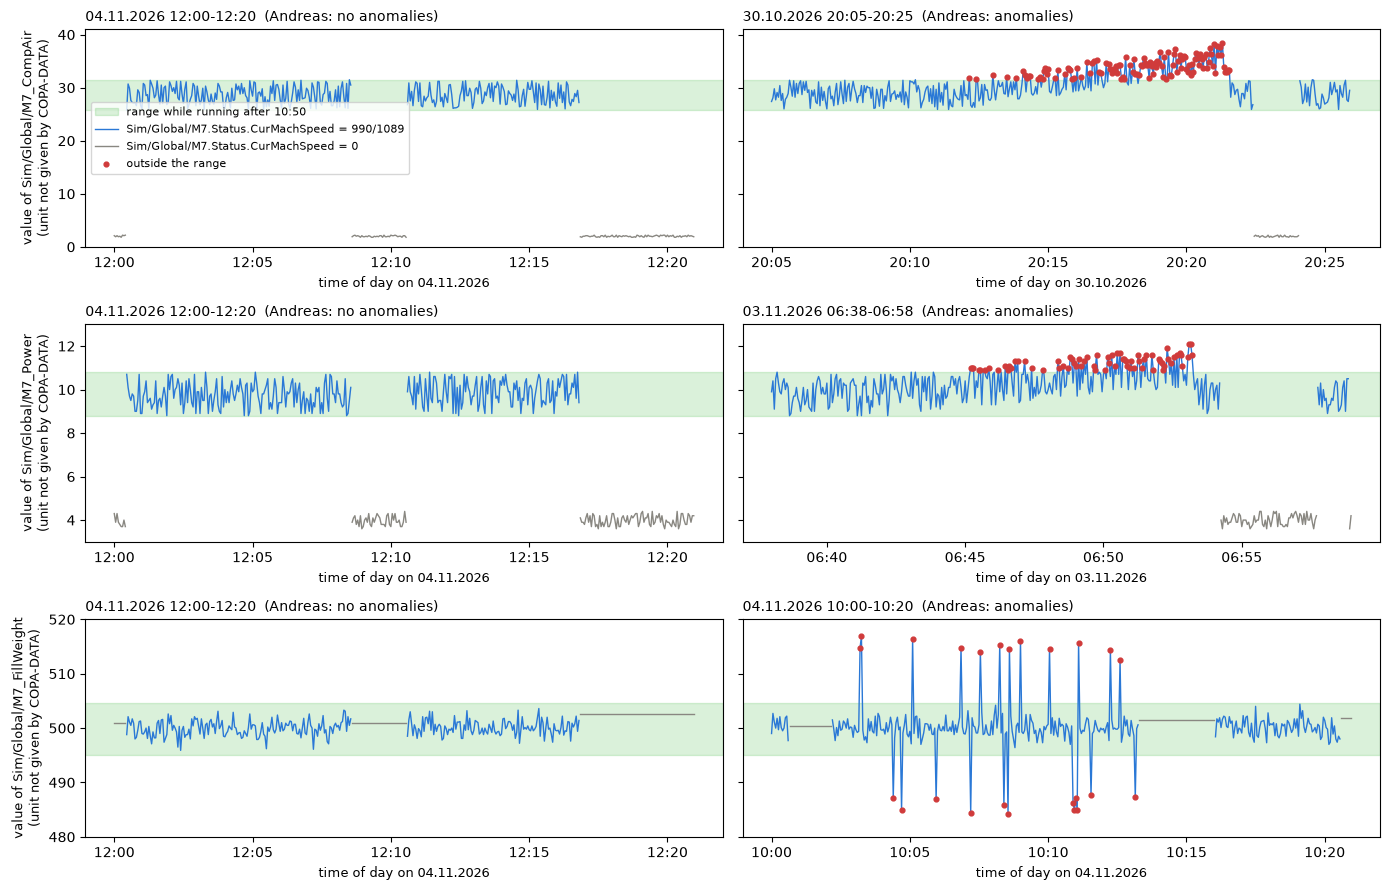

In [10]:
import matplotlib.pyplot as plt, matplotlib.dates as mdates
examples = {"Sim/Global/M7_CompAir": ("2026-10-30 20:05", "2026-10-30 20:25", (25.8, 31.5), (0, 41)),
            "Sim/Global/M7_Power": ("2026-11-03 06:38", "2026-11-03 06:58", (8.8, 10.8), (3, 13)),
            "Sim/Global/M7_FillWeight": ("2026-11-04 10:00", "2026-11-04 10:20", (495.1, 504.6), (480, 520))}
fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharey="row")
for i, (var, (a, b, band, ylim)) in enumerate(examples.items()):
    for j, (t0, t1, title) in enumerate([("2026-11-04 12:00", "2026-11-04 12:20", "Andreas: no anomalies"), (a, b, "Andreas: anomalies")]):
        s = w1.loc[t0:t1]
        run = s[SPEED].isin([990, 1089])
        ax = axes[i, j]
        ax.axhspan(*band, color="#0ca30c", alpha=0.15, label="range while running after 10:50")
        ax.plot(s.index, s[var].where(run), color="#2a78d6", lw=1, label=f"{SPEED} = 990/1089")
        ax.plot(s.index, s[var].where(~run), color="#898781", lw=1, label=f"{SPEED} = 0")
        out = run & ((s[var] < band[0]) | (s[var] > band[1]))
        ax.scatter(s.index[out], s.loc[out, var], s=12, color="#d03b3b", zorder=3, label="outside the range")
        ax.set_ylim(*ylim)
        ax.set_ylabel(f"value of {var}\n(unit not given by COPA-DATA)" if j == 0 else "", fontsize=9)
        ax.set_xlabel(f"time of day on {pd.Timestamp(t0):%d.%m.%Y}", fontsize=9)
        ax.set_title(f"{pd.Timestamp(t0):%d.%m.%Y %H:%M}-{pd.Timestamp(t1):%H:%M}  ({title})", loc="left", fontsize=10)
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
axes[0, 0].legend(loc="center left", fontsize=8)
plt.tight_layout(); plt.show()

## 6 · Where they lie over all days
A plot of all 180,000 values per variable hides 10-minute episodes in the noise band. The highest value per 10 minutes
shows them. Red background = Andreas: anomalies, green = Andreas: no anomalies, white = export of 20.11.2026.

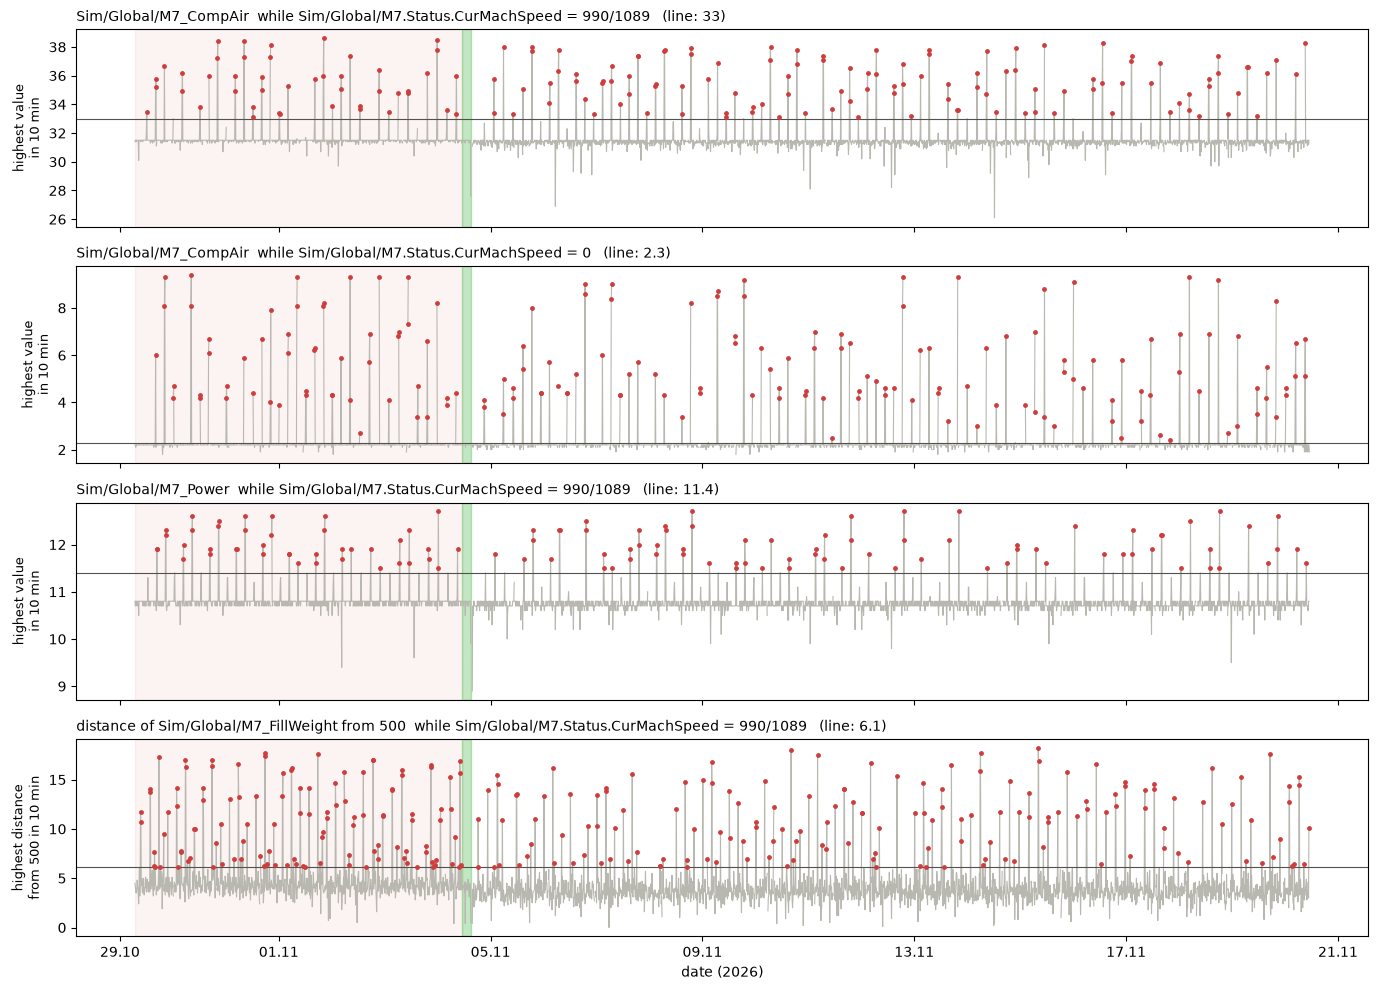

In [11]:
both = pd.concat([w1, w2[w2.index > w1.index.max()]])
run, stop = both[SPEED].isin([990, 1089]), both[SPEED] == 0
panels = [("Sim/Global/M7_CompAir", run, 33), ("Sim/Global/M7_CompAir", stop, 2.3), ("Sim/Global/M7_Power", run, 11.4)]
fig, axes = plt.subplots(len(panels) + 1, 1, figsize=(14, 10), sharex=True)
series = [(f"{v}  while {SPEED} = {'990/1089' if m is run else '0'}", both[v].where(m), thr) for v, m, thr in panels]
series.append((f"distance of Sim/Global/M7_FillWeight from 500  while {SPEED} = 990/1089",
               (both["Sim/Global/M7_FillWeight"] - 500).abs().where(run), 6.1))
for ax, (title, x, thr) in zip(axes, series):
    m10 = x.resample("10min").max()
    ax.axvspan(w1.index.min(), pd.Timestamp("2026-11-04 10:50"), color="#d03b3b", alpha=0.06)
    ax.axvspan(pd.Timestamp("2026-11-04 10:50"), pd.Timestamp("2026-11-04 15:00"), color="#0ca30c", alpha=0.25)
    ax.plot(m10.index, m10, color="#b9b8b0", lw=0.8)
    ax.scatter(m10.index[m10 > thr], m10[m10 > thr], s=6, color="#d03b3b", zorder=3)
    ax.axhline(thr, color="#52514e", lw=0.8); ax.set_title(f"{title}   (line: {thr})", loc="left", fontsize=10)
    ax.set_ylabel("highest distance\nfrom 500 in 10 min" if "distance" in title else "highest value\nin 10 min", fontsize=9)
axes[-1].set_xlabel("date (2026)")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
plt.tight_layout(); plt.show()

## 7 · Your idea: rank the values by how often they occur
Most rows are normal, so very rare values are candidates. Ranked per machine condition
(here `Sim/Global/M7.Status.CurMachSpeed` = 990/1089), otherwise every stop would look rare.

**Sim/Global/M7_FillWeight: 320 different values. Most frequent:**

,rows,share of rows %,"rare (< 1 in 10,000 rows)"
Sim/Global/M7_FillWeight,,,
500.5,3305,2.6801,False
500.1,3290,2.6680,False
499.6,3234,2.6226,False
500.4,3205,2.5990,False
500.3,3160,2.5625,False
499.8,3151,2.5552,False
500.2,3141,2.5471,False
500.7,3098,2.5123,False
499.9,3098,2.5123,False


**Rarest:**

,rows,share of rows %,"rare (< 1 in 10,000 rows)"
Sim/Global/M7_FillWeight,,,
488.7,1,0.0008,True
488.4,1,0.0008,True
491.0,1,0.0008,True
515.0,1,0.0008,True
506.6,1,0.0008,True
490.6,1,0.0008,True
490.8,1,0.0008,True
516.9,1,0.0008,True
516.0,1,0.0008,True


rare rows per Andreas label:
Andreas label
anomalies (until 04.11. ~10:50)    557
Name: count, dtype: int64


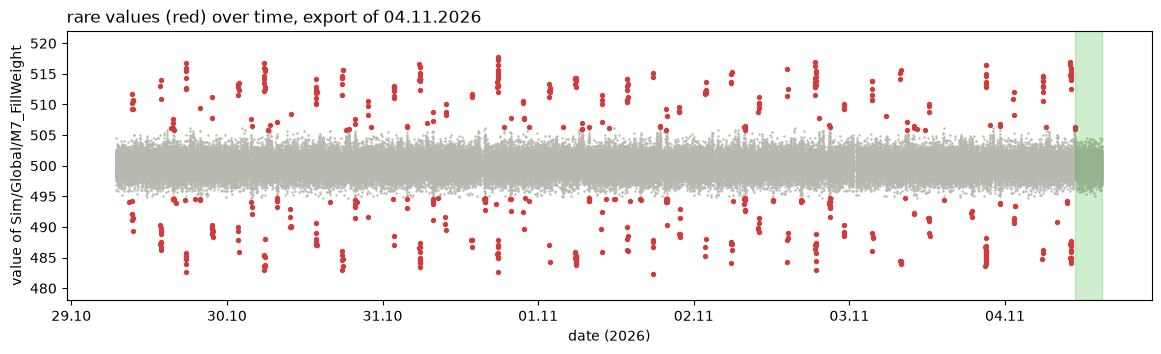

In [12]:
var = "Sim/Global/M7_FillWeight"
vals = w1.loc[w1[SPEED].isin([990, 1089]), var].round(1)
ranking = vals.value_counts().rename("rows").to_frame()
ranking["share of rows %"] = (100 * ranking["rows"] / ranking["rows"].sum()).round(4)
ranking["rare (< 1 in 10,000 rows)"] = ranking["share of rows %"] < 0.01
display(Markdown(f"**{var}: {len(ranking)} different values. Most frequent:**")); display(ranking.head(10))
display(Markdown("**Rarest:**")); display(ranking.tail(10))
rare_values = set(ranking.index[ranking["rare (< 1 in 10,000 rows)"]])
is_rare = w1[SPEED].isin([990, 1089]) & w1[var].round(1).isin(rare_values)
print("rare rows per Andreas label:"); print(w1.loc[is_rare, "Andreas label"].value_counts())
fig, ax = plt.subplots(figsize=(14, 3.5))
ok = w1[SPEED].isin([990, 1089])
ax.scatter(w1.index[ok], w1.loc[ok, var], s=0.5, color="#b9b8b0", rasterized=True)
ax.scatter(w1.index[is_rare], w1.loc[is_rare, var], s=8, color="#d03b3b")
ax.axvspan(pd.Timestamp("2026-11-04 10:50"), pd.Timestamp("2026-11-04 15:00"), color="#0ca30c", alpha=0.2)
ax.set_ylim(478, 522); ax.set_ylabel(f"value of {var}"); ax.set_xlabel("date (2026)")
ax.set_title("rare values (red) over time, export of 04.11.2026", loc="left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m")); plt.show()

## 8 · The full pipeline (about 30 s): episodes, start times, research questions
`analysis/run_analysis.py` repeats the steps above for all three variables and both exports, groups flagged rows into
episodes (flags of one variable less than 5 minutes apart) and computes the first answers to the research questions.

In [13]:
import subprocess, sys, json
r = subprocess.run([sys.executable, "analysis/run_analysis.py", "--out", "results"], capture_output=True, text=True)
print(r.stdout[-800:])
if r.returncode != 0:
    print(r.stderr[-3000:]); raise RuntimeError("pipeline failed")
RES = REPO / "results"; FIG = RES / "figures"; TAB = RES / "tables"
def show(name, width=1150): display(Image(filename=str(FIG / name), width=width))

[   0.0s] loading raw exports
[   6.1s] rule hits per day + explainer figures
[   7.1s] rolling columns
[   7.5s] characterisation of export 04.11.2026
[   7.7s] method: rare values
[   9.0s] method: outside clean-window range -> episodes
[  10.3s] RQ1 methods
[  12.4s] RQ2 online vs batch
[  12.7s] RQ3 sampling interval
[  17.7s] RQ3 hysteresis
[  23.0s] slide figures
[  23.5s] done



In [14]:
eps = pd.read_csv(TAB / "episodes_by_size_export_2026-11-04.csv")
display(Markdown("**Largest episodes, export of 04.11.2026** (excess in standard deviations of Andreas' clean window)"))
display(eps.head(15))
print(eps.groupby(["Andreas label", "variable"]).size())

**Largest episodes, export of 04.11.2026** (excess in standard deviations of Andreas' clean window)

,rank,variable,start,end,duration_s,flagged rows,column with largest excess,value at peak,peak time,excess in clean SD,machine at peak,run_id,Andreas label
0,1,Sim/Global/M7_CompAir,2026-10-30 08:12:00,2026-10-30 08:21:33,573.0,189,Sim/Global/M7_CompAir,9.4,2026-10-30 08:21:33,56.785029,stopped: CurMachSpeed 0,15,anomalies (until 04.11. ~10:50)
1,2,Sim/Global/M7_CompAir,2026-11-02 08:17:21,2026-11-02 08:27:51,630.0,208,Sim/Global/M7_CompAir,9.3,2026-11-02 08:27:45,55.982459,stopped: CurMachSpeed 0,61,anomalies (until 04.11. ~10:50)
2,3,Sim/Global/M7_CompAir,2026-11-01 08:12:30,2026-11-01 08:21:36,546.0,183,Sim/Global/M7_CompAir,9.3,2026-11-01 08:21:33,55.982459,stopped: CurMachSpeed 0,45,anomalies (until 04.11. ~10:50)
3,4,Sim/Global/M7_CompAir,2026-11-02 21:26:54,2026-11-02 21:35:24,510.0,171,Sim/Global/M7_CompAir,9.3,2026-11-02 21:35:15,55.982459,stopped: CurMachSpeed 0,68,anomalies (until 04.11. ~10:50)
4,5,Sim/Global/M7_CompAir,2026-11-03 10:35:18,2026-11-03 10:43:30,492.0,159,Sim/Global/M7_CompAir,9.3,2026-11-03 10:42:48,55.982459,stopped: CurMachSpeed 0,75,anomalies (until 04.11. ~10:50)
5,6,Sim/Global/M7_CompAir,2026-10-29 20:13:45,2026-10-29 20:21:33,468.0,152,Sim/Global/M7_CompAir,9.3,2026-10-29 20:21:24,55.982459,stopped: CurMachSpeed 0,8,anomalies (until 04.11. ~10:50)
6,7,Sim/Global/M7_CompAir,2026-11-01 20:14:06,2026-11-01 20:22:21,495.0,156,Sim/Global/M7_CompAir,8.2,2026-11-01 20:20:03,47.154191,stopped: CurMachSpeed 0,53,anomalies (until 04.11. ~10:50)
7,8,Sim/Global/M7_CompAir,2026-11-03 23:42:27,2026-11-03 23:50:33,486.0,148,Sim/Global/M7_CompAir,8.2,2026-11-03 23:48:42,47.154191,stopped: CurMachSpeed 0,82,anomalies (until 04.11. ~10:50)
8,9,Sim/Global/M7_CompAir,2026-10-31 20:12:09,2026-10-31 20:21:45,576.0,181,Sim/Global/M7_CompAir,7.9,2026-10-31 20:20:00,44.746481,stopped: CurMachSpeed 0,38,anomalies (until 04.11. ~10:50)
9,10,Sim/Global/M7_CompAir,2026-11-03 06:12:57,2026-11-03 06:20:24,447.0,133,Sim/Global/M7_CompAir,7.0,2026-11-03 06:20:21,37.523352,stopped: CurMachSpeed 0,72,anomalies (until 04.11. ~10:50)


Andreas label                    variable                
anomalies (until 04.11. ~10:50)  Sim/Global/M7_CompAir       39
                                 Sim/Global/M7_FillWeight    88
                                 Sim/Global/M7_Power         35
dtype: int64


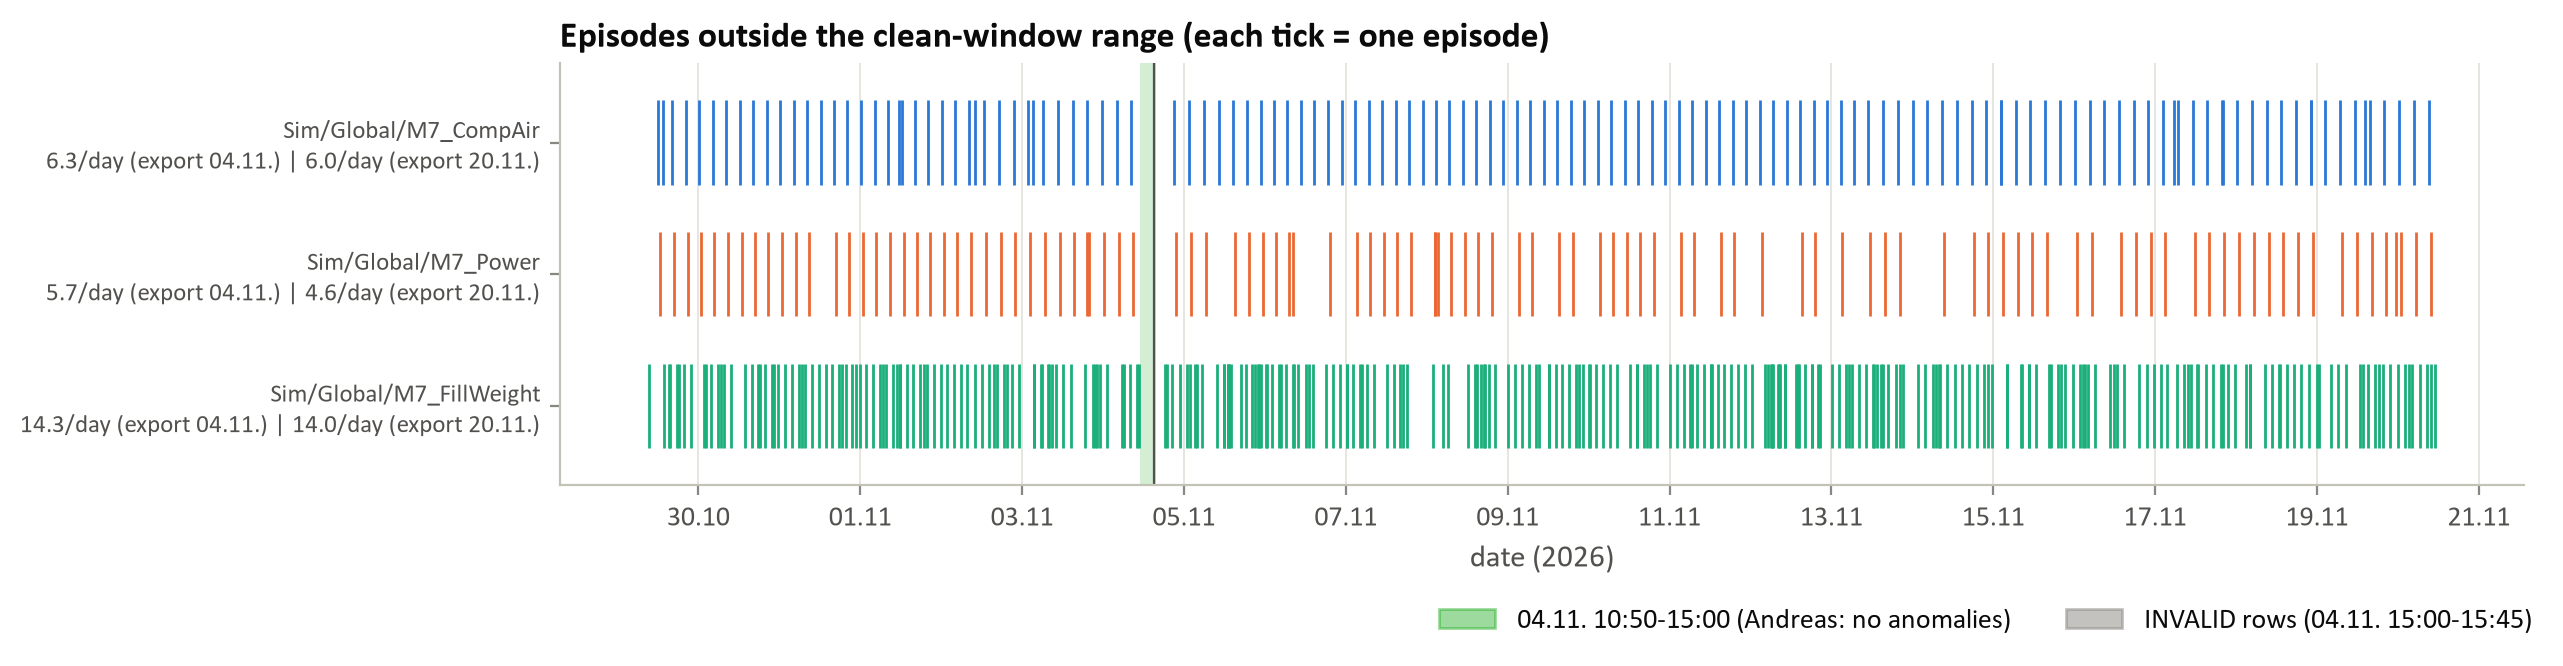

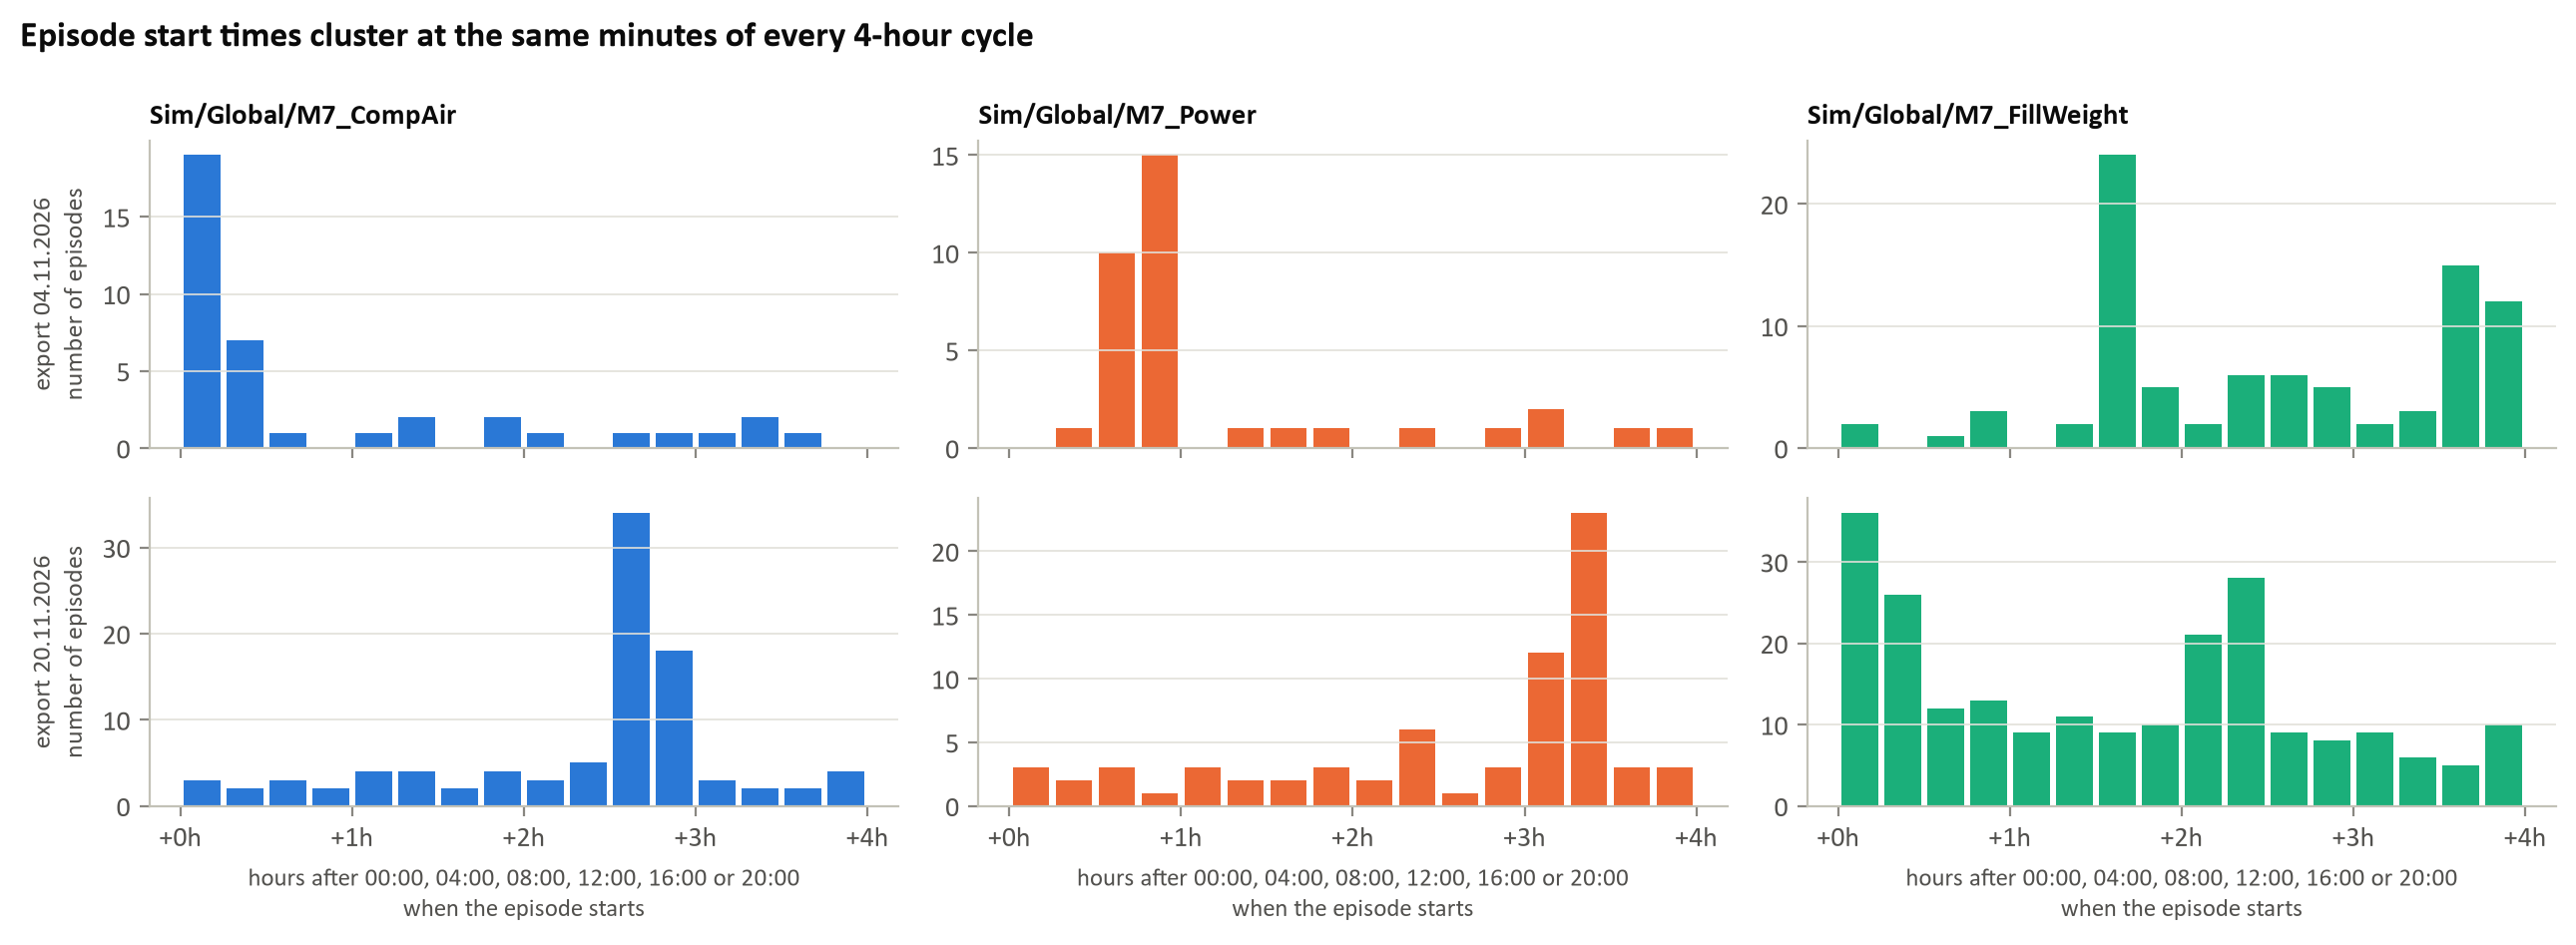

,export,variable,episodes,share starting in the busiest 30 min of the 4 h cycle %,busiest 30 min (h:mm after 00/04/08/12/16/20 h),if start times were random %
0,Export 04.11.2026 (cyclic 3 s),Sim/Global/M7_CompAir,39,66.666667,0:00-0:30,12.5
1,Export 04.11.2026 (cyclic 3 s),Sim/Global/M7_Power,35,71.428571,0:30-1:00,12.5
2,Export 04.11.2026 (cyclic 3 s),Sim/Global/M7_FillWeight,88,34.090909,1:34-2:04,12.5
3,Export 20.11.2026 (cyclic 10 s),Sim/Global/M7_CompAir,95,54.736842,2:19-2:49,12.5
4,Export 20.11.2026 (cyclic 10 s),Sim/Global/M7_Power,72,52.777778,3:03-3:33,12.5
5,Export 20.11.2026 (cyclic 10 s),Sim/Global/M7_FillWeight,222,29.729730,0:10-0:40,12.5


In [15]:
show("fig05_episodes_over_time.png")
show("fig10_episode_start_times_4h_cycle.png")
display(pd.read_csv(TAB / "episode_start_times_4h_cycle.csv"))

## 9 · Research questions: first answers (export of 04.11.2026)

**RQ1: three methods**

,method,flagged rows %,alarm events until 04.11. 10:50,alarm events 04.11. 10:50-15:00,alarm events per hour until 10:50,alarm events per hour 10:50-15:00,false alarms per day,clean hours,anomaly hours,episodes detected %,median delay s,alarms that hit an episode %,median warning before peak s,episodes detected % | Sim/Global/M7_CompAir,episodes detected % | Sim/Global/M7_Power,episodes detected % | Sim/Global/M7_FillWeight
0,"rare values (< 1 in 10,000 rows)",0.39,165,0,1.11,0.0,0.0,4.17,148.0,59.26,0.0,83.03,40.5,41.03,17.14,84.09
1,outside clean-window range,7.21,194,0,1.31,0.0,0.0,4.17,148.0,100.00,0.0,100.00,342.0,100.00,100.00,100.00
2,Isolation Forest,0.94,96,0,0.65,0.0,0.0,4.17,148.0,49.38,154.5,100.00,175.5,58.97,65.71,38.64


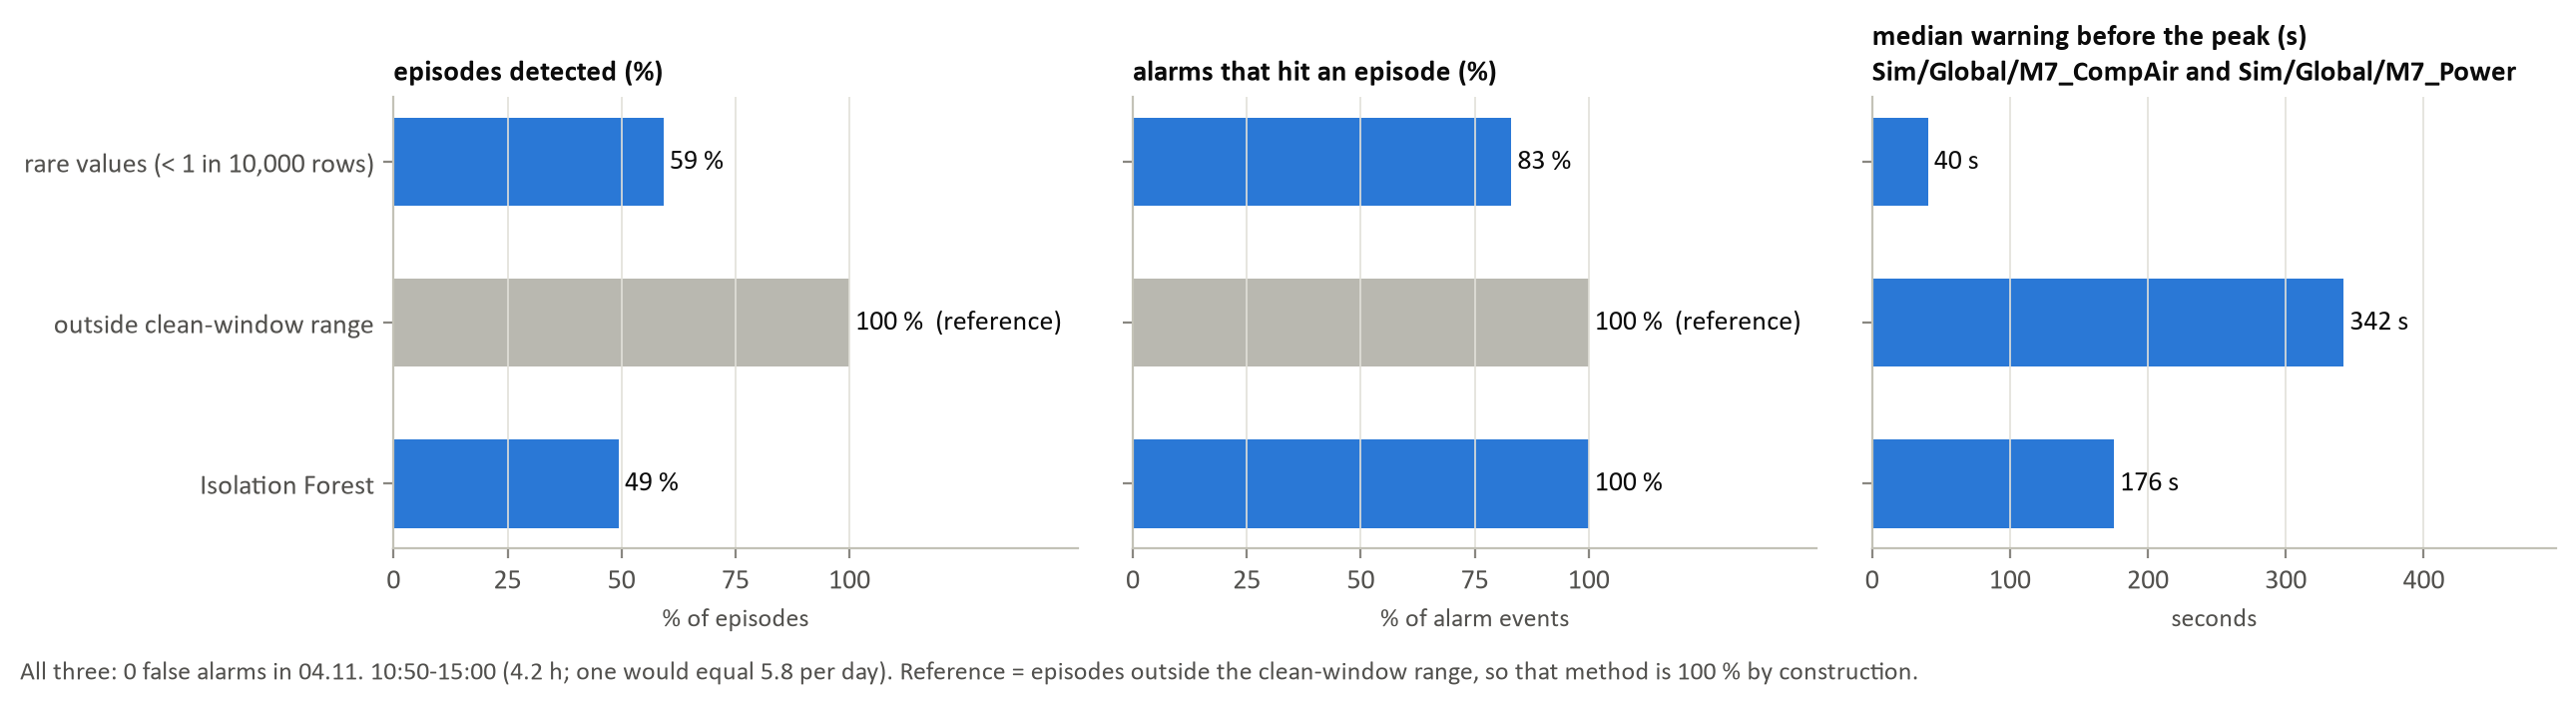

In [16]:
display(Markdown("**RQ1: three methods**"))
display(pd.read_csv(TAB / "rq1_methods.csv").round(2))
show("fig06_rq1_methods.png")

**RQ2: online (only past values) vs. batch (centred window)**

,variable,batch episodes,batch episodes also found online %,median extra delay online s,p90 extra delay online s
0,Sim/Global/M7_CompAir,36,100.0,0.0,9.0
1,Sim/Global/M7_Power,38,92.1,30.0,30.0
2,Sim/Global/M7_FillWeight,91,95.6,30.0,30.0


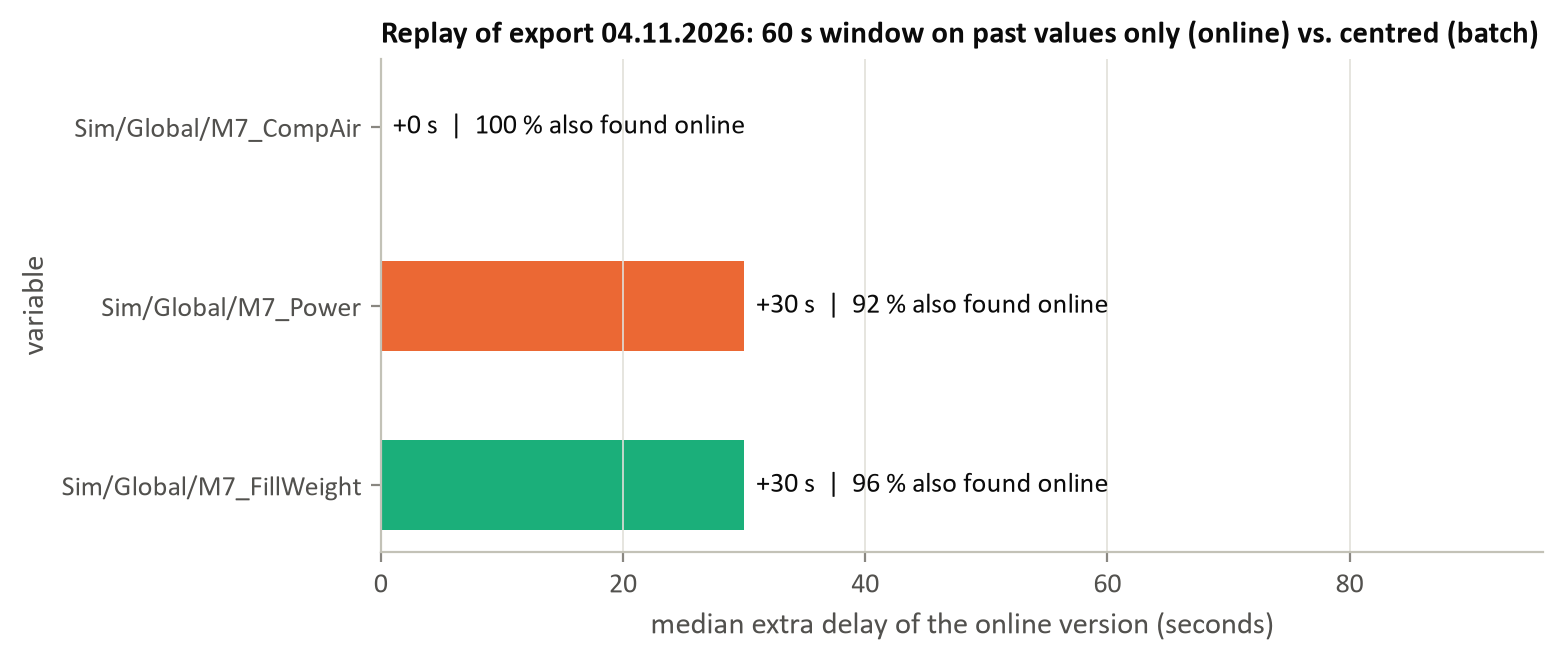

In [17]:
display(Markdown("**RQ2: online (only past values) vs. batch (centred window)**"))
display(pd.read_csv(TAB / "rq2_online_vs_batch.csv").round(1))
show("fig07_rq2_online_vs_batch.png", width=800)

**RQ3: sampling interval and recording on change**

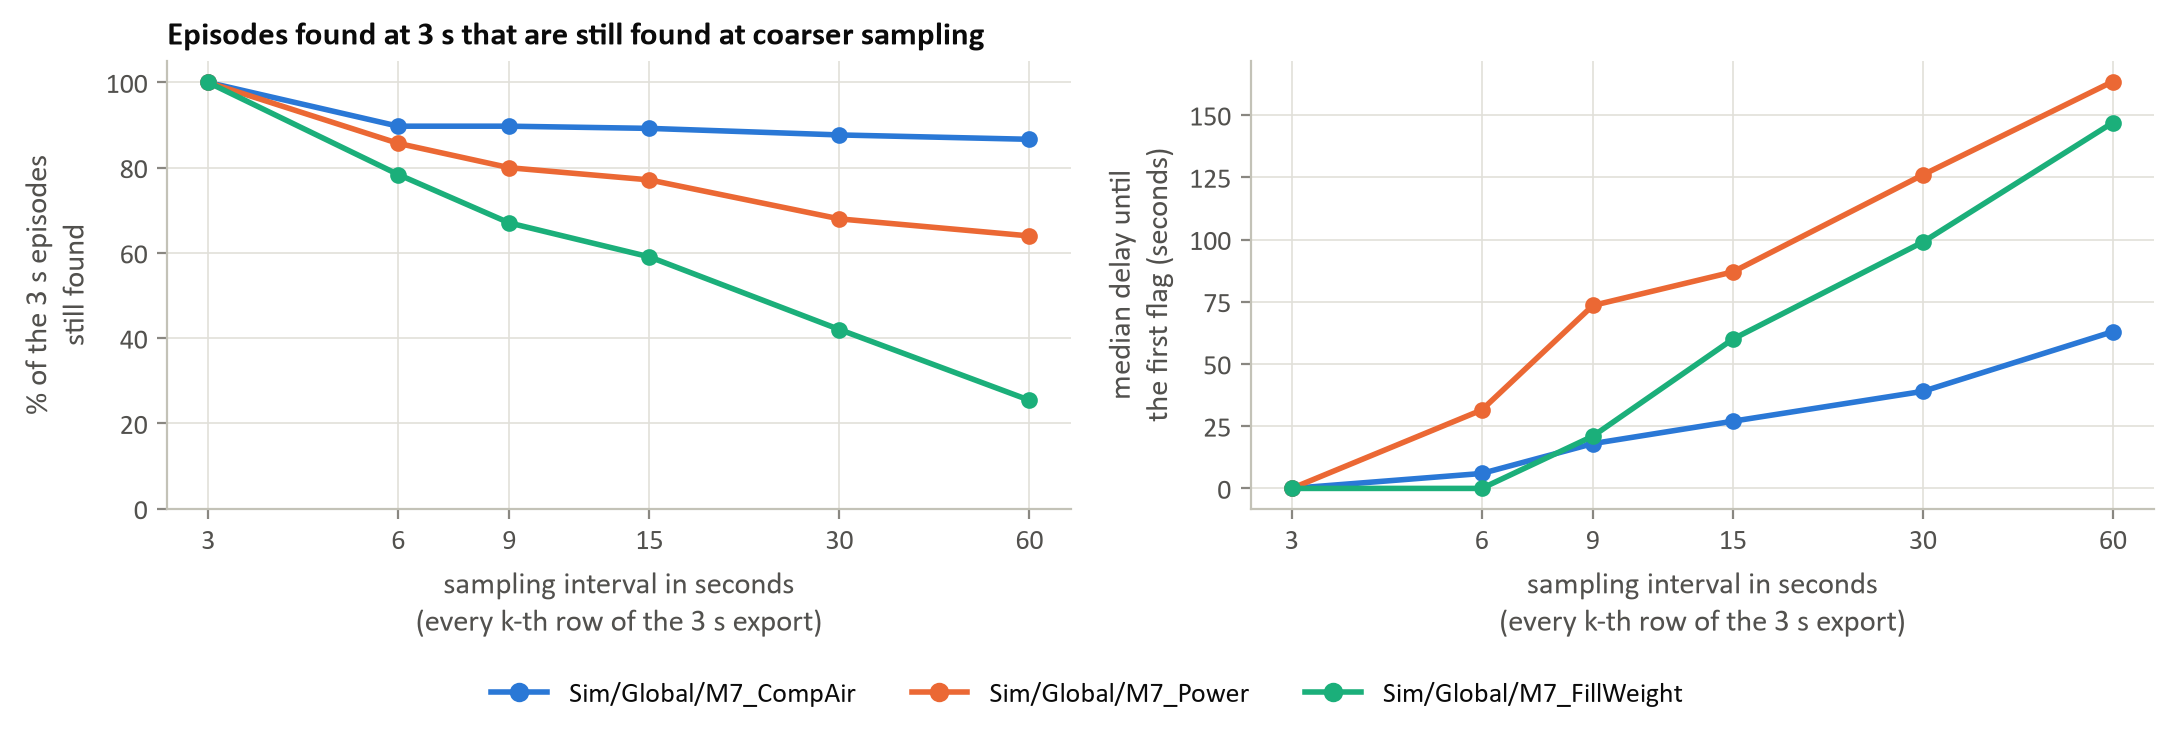

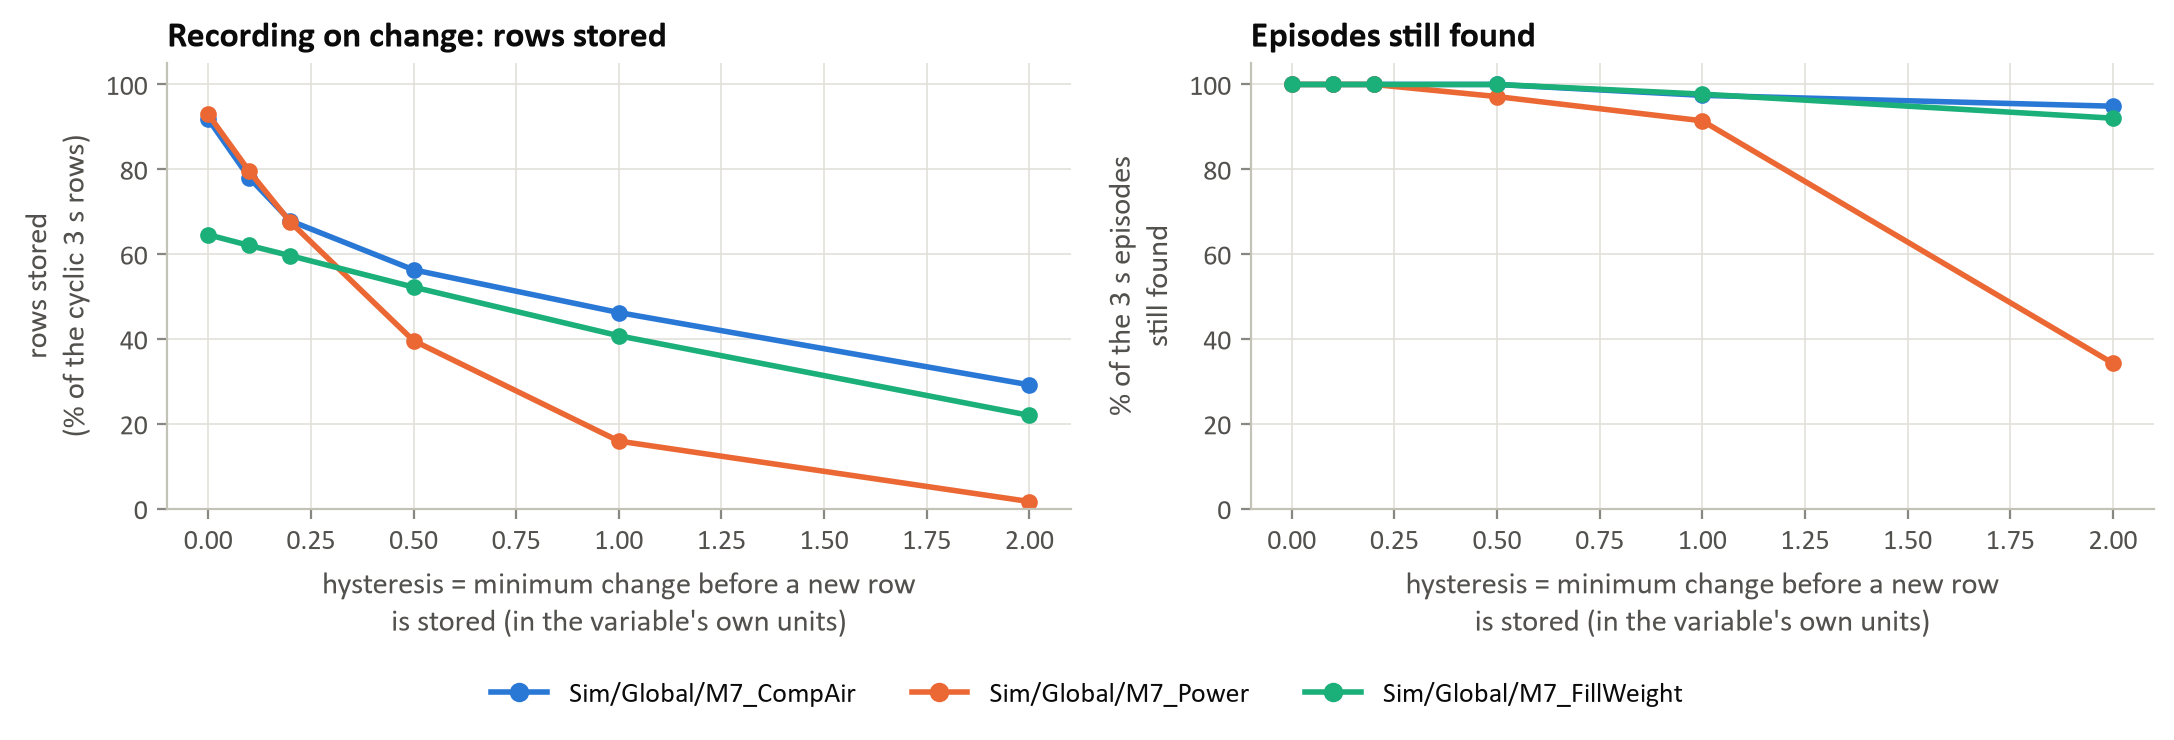

,interval s,variable,phase offsets averaged,detected %,median delay s,rows per day per variable
0,3,Sim/Global/M7_CompAir,1,100.0,0.0,28800.0
1,3,Sim/Global/M7_Power,1,100.0,0.0,28800.0
2,3,Sim/Global/M7_FillWeight,1,100.0,0.0,28800.0
3,6,Sim/Global/M7_CompAir,2,89.7,6.0,14400.0
4,6,Sim/Global/M7_Power,2,85.7,31.5,14400.0
5,6,Sim/Global/M7_FillWeight,2,78.4,0.0,14400.0
6,9,Sim/Global/M7_CompAir,3,89.7,18.0,9600.0
7,9,Sim/Global/M7_Power,3,80.0,73.5,9600.0
8,9,Sim/Global/M7_FillWeight,3,67.0,21.0,9600.0
9,15,Sim/Global/M7_CompAir,5,89.2,27.0,5760.0


In [18]:
display(Markdown("**RQ3: sampling interval and recording on change**"))
show("fig08_rq3_sampling_interval.png")
show("fig09_rq3_hysteresis.png")
display(pd.read_csv(TAB / "rq3_sampling_interval.csv").round(1))

## 10 · Explore yourself
Pick a variable and a time window, then press ▶ again. In the browser version of Colab the fields appear as a form.

In [ ]:
# @title Explorer
VARIABLE = "Sim/Global/M7_CompAir"   # @param ["Sim/Global/M7_CompAir", "Sim/Global/M7_Power", "Sim/Global/M7_FillWeight", "Sim/Global/M7.Admin.ProductData_DefectiveCount", "Sim/Global/M7.Status.StateCurrent"]
START = "2026-10-30 20:00"           # @param {type:"string"}
END = "2026-10-30 20:30"             # @param {type:"string"}

import plotly.graph_objects as go
from plotly.subplots import make_subplots
w = w1 if pd.Timestamp(START) < pd.Timestamp("2026-11-04 15:00") else w2
s = w.loc[START:END]
fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.7, 0.3], subplot_titles=[VARIABLE, SPEED])
fig.add_trace(go.Scatter(x=s.index, y=s[VARIABLE], mode="lines+markers", marker=dict(size=3), line=dict(width=1)), row=1, col=1)
fig.add_trace(go.Scatter(x=s.index, y=s[SPEED], mode="lines", line=dict(width=1, color="#898781")), row=2, col=1)
fig.update_layout(height=600, showlegend=False, template="simple_white", title=f"{START} to {END} ({s['Andreas label'].iloc[0]})")
fig.update_yaxes(title_text=f"value of {VARIABLE}", row=1, col=1)
fig.update_yaxes(title_text="CurMachSpeed value", row=2, col=1)
fig.update_xaxes(title_text="time", row=2, col=1)
fig.show()